# Transformaciones de datos con PyTorch

Este es un notebook de prueba. Se aplican transformaciones de datos a las imágenes centradas de fracciones de perfiles de vasijas.

Se utiliza PyTorch para crear un dataset que permiten aplicar transformaciones como rotación, escalado y volteo aleatorio a las imágenes durante el entrenamiento de modelos de aprendizaje profundo.

In [1]:
from vasijas.config import load_config
from vasijas.paths import ProjectPaths

from vasijas.transformaciones import (
    ConfiguracionTransformaciones,
    crear_dataset_imagenes,
    graficar_muestras_dataset,
)

import matplotlib.pyplot as plt

plt.style.use("ggplot")

## Configuración de transformaciones y parámetros del dataloader

In [2]:
CONFIG = load_config()
PATHS = ProjectPaths.from_root(CONFIG.project_root)

CONFIG_TRANSFORMACIONES = ConfiguracionTransformaciones(
    img_size=128,
    flip_probability=0.7,
    scaling_factor_interval=(0.7, 1.0),
    rotation_degrees=(0, 360),
    pixel_fill=(255, 255, 255),
)
BATCH_SIZE = 4

### Parámetros configurados

In [3]:
print(f"Tamaño de imagen por lado: {CONFIG_TRANSFORMACIONES.img_size}")
print(f"Probabilidad de volteo horizontal: {CONFIG_TRANSFORMACIONES.flip_probability}")
print(f"Intervalo de escalado: {CONFIG_TRANSFORMACIONES.scaling_factor_interval}")
print(f"Rango de rotación: {CONFIG_TRANSFORMACIONES.rotation_degrees}")
print(f"Color de relleno de píxeles: {CONFIG_TRANSFORMACIONES.pixel_fill}")
print(f"Tamaño del lote: {BATCH_SIZE}")

Tamaño de imagen por lado: 128
Probabilidad de volteo horizontal: 0.7
Intervalo de escalado: (0.7, 1.0)
Rango de rotación: (0, 360)
Color de relleno de píxeles: (255, 255, 255)
Tamaño del lote: 4


## Creación del dataset y dataloader con transformaciones

In [4]:
dataset_transformado = crear_dataset_imagenes(
    ruta_datos=PATHS.DATA_CENTRADOS, config=CONFIG_TRANSFORMACIONES
)

print(f"Es tamaño del dataset es de {len(dataset_transformado)} imágenes.")
print("Clases procesadas:")
for clase in dataset_transformado.classes:
    print(f"  {clase}")

Es tamaño del dataset es de 19458 imágenes.
Clases procesadas:
  clase01
  clase02
  clase03
  clase04
  clase05
  clase06
  clase07
  clase08
  clase09
  clase10
  clase11


## Visualización de muestras transformadas

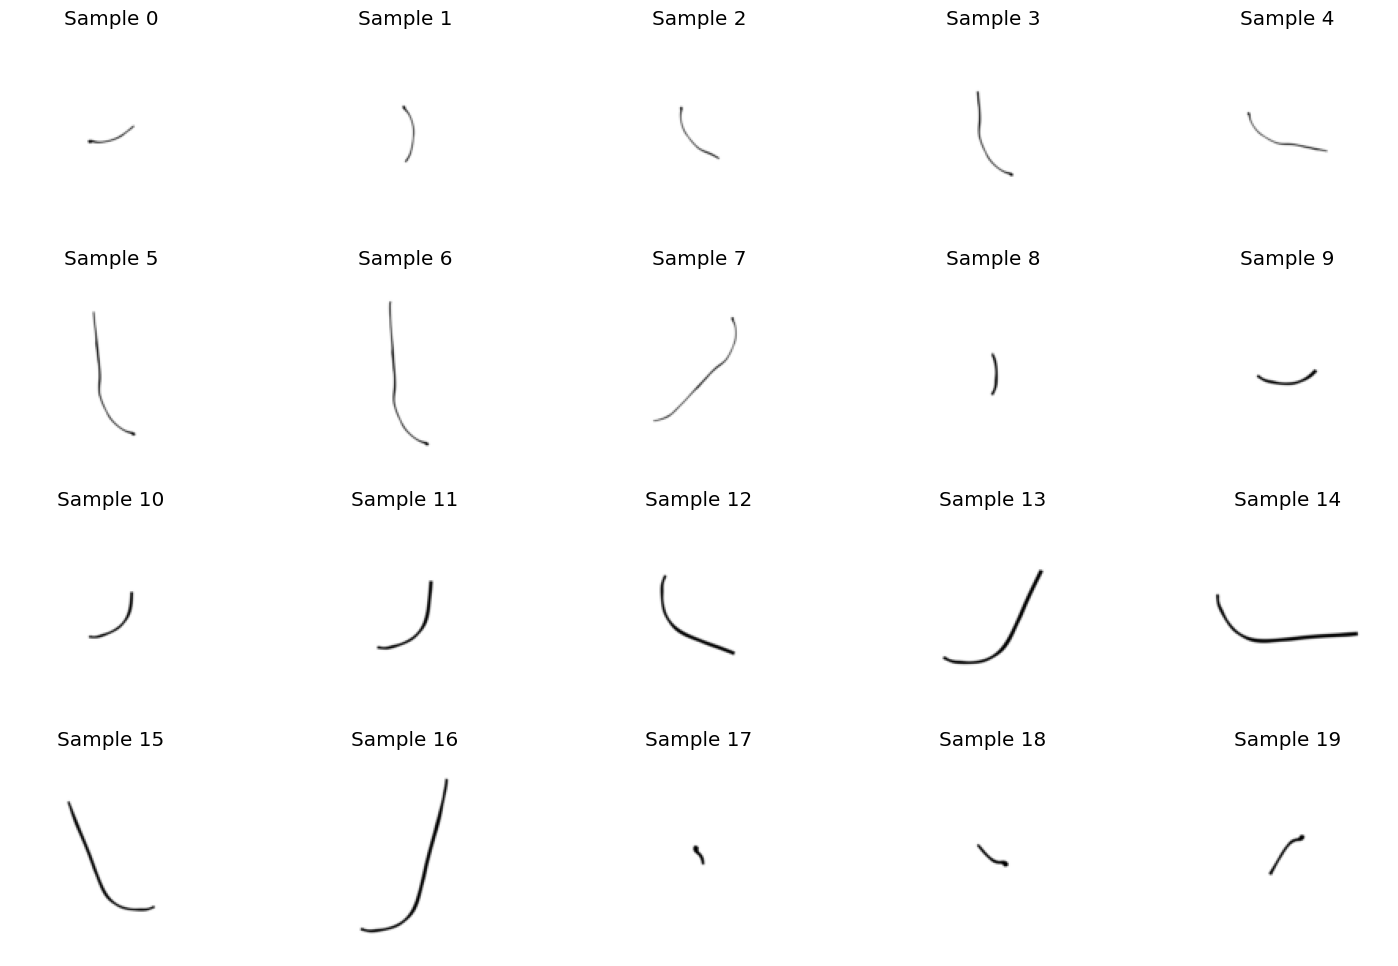

In [5]:
figura = graficar_muestras_dataset(
    dataset=dataset_transformado,
    cantidad=20,
    offset=10,
    columnas=5,
)

plt.show()